In [ ]:
import os, sys, yaml, torch, numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader
from tqdm import tqdm
import sklearn

sys.path.insert(0, os.getcwd())
from joint_embedding_learning.utils.models_setup import get_model
from joint_embedding_learning.data.datasets import get_all_contrastive_datasets

device        = "cuda:0"
dataset_name  = "dataset_cross_modal_tri"
model_name    = "cross_modal_vae3"
run_name      = "dataset_cross_modal_tri_run_tri_recon_20260510_025144"

checkpoint_dir = os.path.join("checkpoints", "cross_modal_tri", model_name, run_name)

with open(os.path.join("config", "datasets_config.yaml")) as f:
    dataset_details = yaml.safe_load(f)[dataset_name]
with open(os.path.join(checkpoint_dir, "model_details.yaml")) as f:
    model_details = yaml.safe_load(f)

model = get_model(model_name, model_details).to(device)
model.load_state_dict(torch.load(os.path.join(checkpoint_dir, "model.pt"), map_location=device, weights_only=False))
model.eval()
print(f"Loaded: {checkpoint_dir}")

train_datasets, val_datasets, _ = get_all_contrastive_datasets(dataset_name, data_split="train", device="cpu")
print("Train:", {k: len(v) for k, v in train_datasets.items()})
print("Val:  ", {k: len(v) for k, v in val_datasets.items()})

/home/junsung/anaconda3/envs/cmt/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/junsung/anaconda3/envs/cmt/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Loaded: checkpoints/cross_modal_tri/cross_modal_vae3/dataset_cross_modal_tri_run_tri_minimal_20260507_190114
Train: {'de': 2601, 'ef': 4513, 'fd': 2685}
Val:   {'de': 651, 'ef': 1129, 'fd': 672}


In [2]:
# ===== 임베딩 추출 =====
@torch.no_grad()
def extract_pair_mu(dataset, pair_name, model, device, batch_size=128):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, drop_last=False)
    all_mu_a, all_mu_b = [], []
    for (xa, xb), _ in tqdm(loader, desc=pair_name):
        out = model.forward_pair(xa.to(device), xb.to(device), pair_name)
        all_mu_a.append(out["mu_a"].cpu())
        all_mu_b.append(out["mu_b"].cpu())
    return torch.cat(all_mu_a), torch.cat(all_mu_b)

# Train
mu_D_de_tr, mu_E_de_tr = extract_pair_mu(train_datasets["de"], "de", model, device)
mu_E_ef_tr, mu_F_ef_tr = extract_pair_mu(train_datasets["ef"], "ef", model, device)
mu_F_fd_tr, mu_D_fd_tr = extract_pair_mu(train_datasets["fd"], "fd", model, device)

# Val
mu_D_de_v, mu_E_de_v = extract_pair_mu(val_datasets["de"], "de", model, device)
mu_E_ef_v, mu_F_ef_v = extract_pair_mu(val_datasets["ef"], "ef", model, device)
mu_F_fd_v, mu_D_fd_v = extract_pair_mu(val_datasets["fd"], "fd", model, device)

print("Done.")

fd: 100%|██████████| 6/6 [00:00<00:00,  7.64it/s]

Done.


[Train] t-SNE on 19598 points (DE:2601×2, EF:4513×2, FD:2685×2) ...


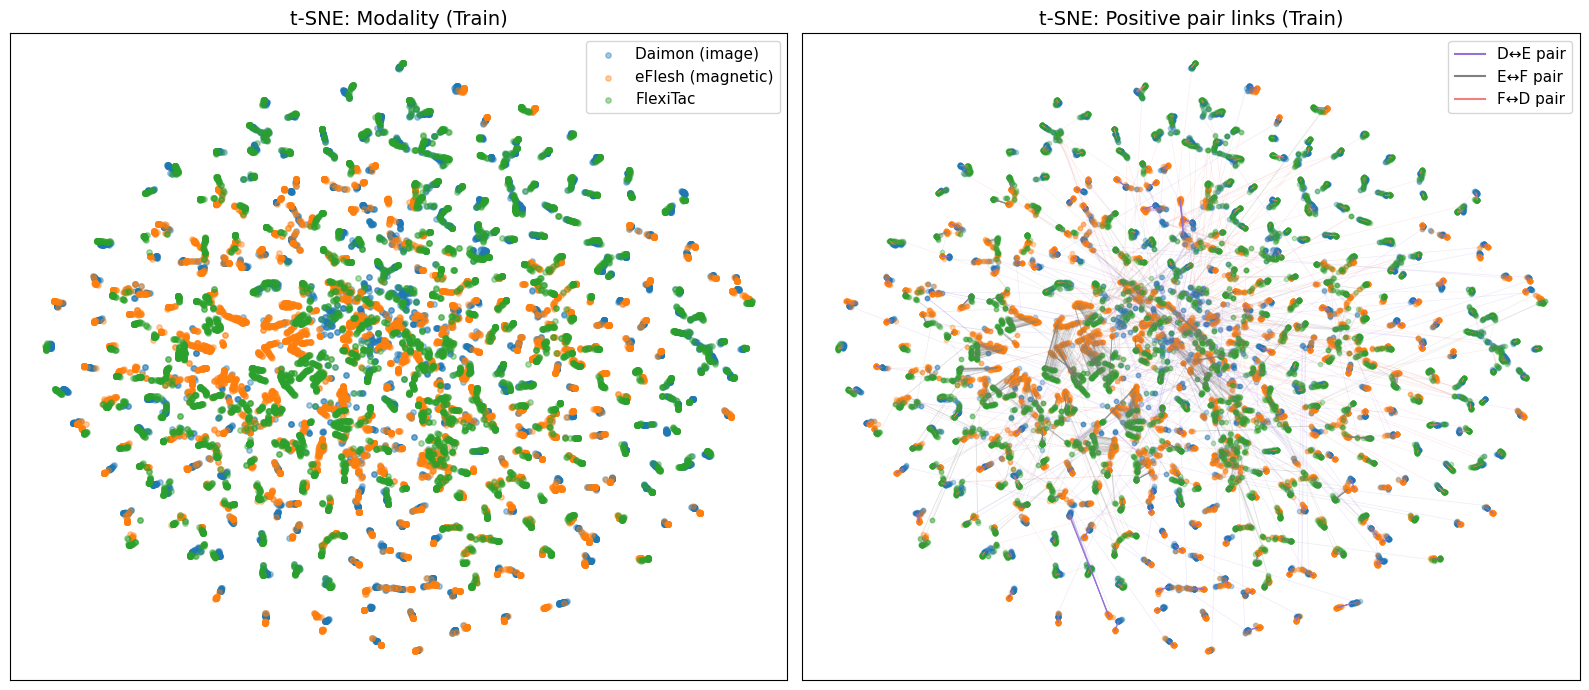

Saved: eval_results/cross_modal_vae3_tsne_train.png
[Val] t-SNE on 4904 points (DE:651×2, EF:1129×2, FD:672×2) ...


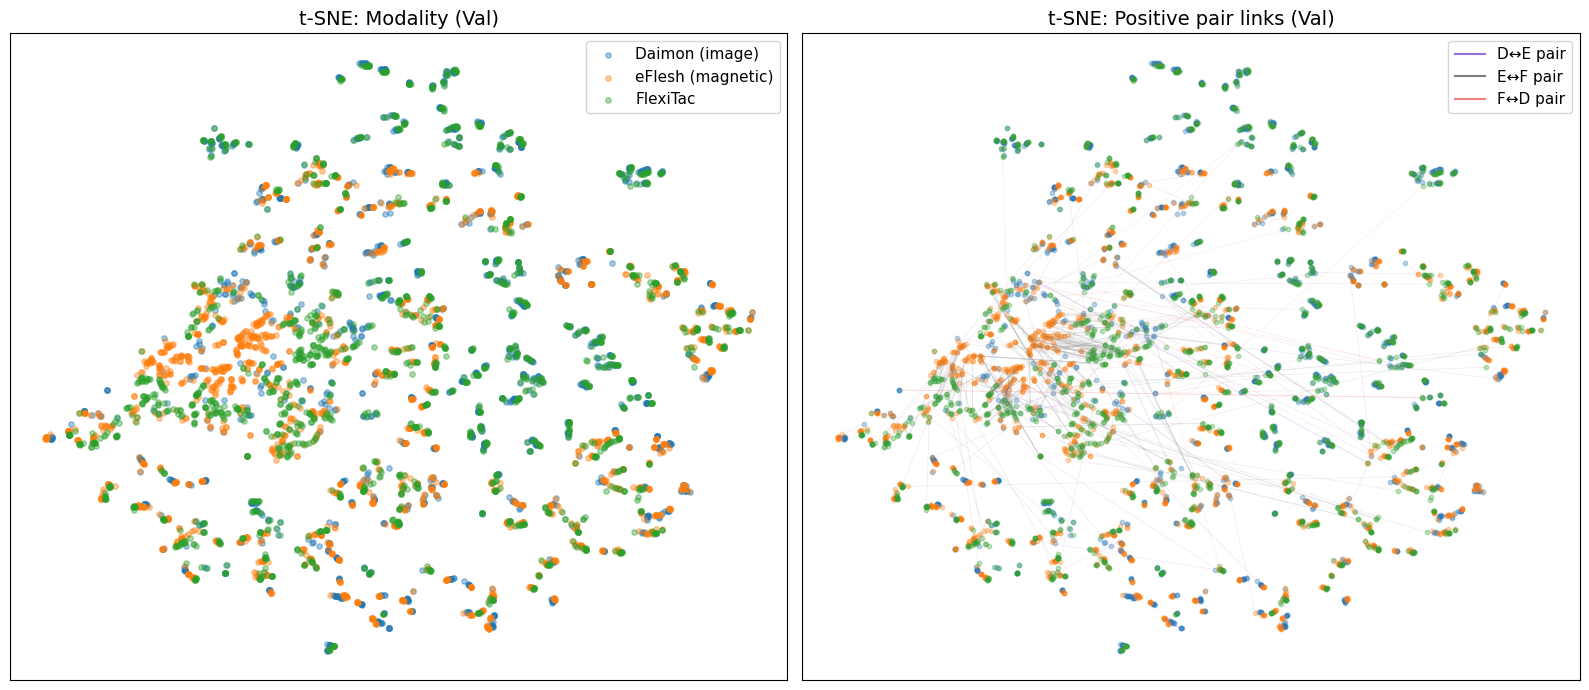

Saved: eval_results/cross_modal_vae3_tsne_val.png


In [ ]:
# ===== t-SNE 시각화 =====
# pair 단위로 aligned 임베딩 유지 → positive line은 같은 에피소드/프레임 매칭
#
# 구조:
#   de_pair → (D_de[i], E_de[i])  같은 에피소드·프레임
#   ef_pair → (E_ef[i], F_ef[i])  같은 에피소드·프레임
#   fd_pair → (F_fd[i], D_fd[i])  같은 에피소드·프레임
#
# 모든 임베딩을 t-SNE에 넣고, pair 내 같은 인덱스끼리 선을 그림

def make_tsne(points, perplexity=30, seed=42):
    kw = dict(n_components=2, perplexity=perplexity, random_state=seed)
    if tuple(int(x) for x in sklearn.__version__.split(".")[:2]) >= (1, 0):
        kw["max_iter"] = 1000
    else:
        kw["n_iter"] = 1000
    return TSNE(**kw).fit_transform(points)


def plot_tsne_pairs(mu_D_de, mu_E_de, mu_E_ef, mu_F_ef, mu_F_fd, mu_D_fd,
                    split_name, save_path, n_lines=10**9):
    """
    6개 임베딩 블록을 concat하여 t-SNE 수행.
    positive line은 pair 내 같은 인덱스(=같은 에피소드/프레임)끼리 연결.
    """
    z_D_de = F.normalize(mu_D_de, dim=1).numpy()
    z_E_de = F.normalize(mu_E_de, dim=1).numpy()
    z_E_ef = F.normalize(mu_E_ef, dim=1).numpy()
    z_F_ef = F.normalize(mu_F_ef, dim=1).numpy()
    z_F_fd = F.normalize(mu_F_fd, dim=1).numpy()
    z_D_fd = F.normalize(mu_D_fd, dim=1).numpy()

    n_de, n_ef, n_fd = len(z_D_de), len(z_E_ef), len(z_F_fd)

    combined = np.concatenate([z_D_de, z_E_de, z_E_ef, z_F_ef, z_F_fd, z_D_fd], axis=0)
    print(f"[{split_name}] t-SNE on {combined.shape[0]} points "
          f"(DE:{n_de}×2, EF:{n_ef}×2, FD:{n_fd}×2) ...")
    tsne_2d = make_tsne(combined)

    # 각 블록의 t-SNE 좌표 분리
    off = 0
    t_D_de = tsne_2d[off:off+n_de]; off += n_de
    t_E_de = tsne_2d[off:off+n_de]; off += n_de
    t_E_ef = tsne_2d[off:off+n_ef]; off += n_ef
    t_F_ef = tsne_2d[off:off+n_ef]; off += n_ef
    t_F_fd = tsne_2d[off:off+n_fd]; off += n_fd
    t_D_fd = tsne_2d[off:off+n_fd]; off += n_fd

    # 모달리티별로 모아서 scatter
    all_D = np.concatenate([t_D_de, t_D_fd])
    all_E = np.concatenate([t_E_de, t_E_ef])
    all_F = np.concatenate([t_F_ef, t_F_fd])

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))

    # --- Plot 1: 모달리티별 색상 ---
    ax = axes[0]
    ax.scatter(all_D[:, 0], all_D[:, 1], c="tab:blue",   alpha=0.4, s=15, label="Daimon (image)")
    ax.scatter(all_E[:, 0], all_E[:, 1], c="tab:orange", alpha=0.4, s=15, label="eFlesh (magnetic)")
    ax.scatter(all_F[:, 0], all_F[:, 1], c="tab:green",  alpha=0.4, s=15, label="FlexiTac")
    ax.set_title(f"t-SNE: Modality ({split_name})", fontsize=14)
    ax.legend(fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

    # --- Plot 2: Positive pair 연결선 (같은 에피소드/프레임) ---
    ax = axes[1]
    ax.scatter(all_D[:, 0], all_D[:, 1], c="tab:blue",   alpha=0.3, s=10, label="Daimon")
    ax.scatter(all_E[:, 0], all_E[:, 1], c="tab:orange", alpha=0.3, s=10, label="eFlesh")
    ax.scatter(all_F[:, 0], all_F[:, 1], c="tab:green",  alpha=0.3, s=10, label="FlexiTac")

    rng = np.random.RandomState(0)

    # DE pair: D_de[i] ↔ E_de[i]
    idx_de = rng.choice(n_de, size=min(n_lines, n_de), replace=False)
    for k in idx_de:
        ax.plot([t_D_de[k, 0], t_E_de[k, 0]],
                [t_D_de[k, 1], t_E_de[k, 1]], c="mediumpurple", alpha=0.15, linewidth=0.5)

    # EF pair: E_ef[i] ↔ F_ef[i]
    idx_ef = rng.choice(n_ef, size=min(n_lines, n_ef), replace=False)
    for k in idx_ef:
        ax.plot([t_E_ef[k, 0], t_F_ef[k, 0]],
                [t_E_ef[k, 1], t_F_ef[k, 1]], c="gray", alpha=0.15, linewidth=0.5)

    # FD pair: F_fd[i] ↔ D_fd[i]
    idx_fd = rng.choice(n_fd, size=min(n_lines, n_fd), replace=False)
    for k in idx_fd:
        ax.plot([t_F_fd[k, 0], t_D_fd[k, 0]],
                [t_F_fd[k, 1], t_D_fd[k, 1]], c="lightcoral", alpha=0.15, linewidth=0.5)

    from matplotlib.lines import Line2D
    handles = [
        Line2D([], [], color="mediumpurple", lw=1.5, label="D↔E pair"),
        Line2D([], [], color="gray",         lw=1.5, label="E↔F pair"),
        Line2D([], [], color="lightcoral",   lw=1.5, label="F↔D pair"),
    ]
    ax.legend(handles=handles, fontsize=11)
    ax.set_title(f"t-SNE: Positive pair links ({split_name})", fontsize=14)
    ax.set_xticks([]); ax.set_yticks([])

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {save_path}")


os.makedirs("eval_results", exist_ok=True)

# ── Train ──
plot_tsne_pairs(
    mu_D_de_tr, mu_E_de_tr, mu_E_ef_tr, mu_F_ef_tr, mu_F_fd_tr, mu_D_fd_tr,
    "Train", "eval_results/cross_modal_vae3_tsne_train.png",
)

# ── Val ──
plot_tsne_pairs(
    mu_D_de_v, mu_E_de_v, mu_E_ef_v, mu_F_ef_v, mu_F_fd_v, mu_D_fd_v,
    "Val", "eval_results/cross_modal_vae3_tsne_val.png",
)